## **Problem 3**

We use _**`data.csv`**_, a 10×10 histogram, $\epsilon=1.4$, and random seed 5489 with the Mersenne Twister generator.

a. First, we read the data and split both Age and BloodPressure into 10 bins. This gives 100 groups in total. I count how many people fall into each group and plot the result as a 3D histogram.

(a) Original histogram counts:
[[   0    0    1    2    5    4    1    0    0    0]
 [   0    3   35   56   73   28    2    0    0    0]
 [   6   25  189  491  439  172   26    2    1    0]
 [   5   78  470 1180 1186  515   92   13    3    0]
 [   3   74  483 1148 1172  641  294  153   36    2]
 [   2   26  184  454  620  797  907  586  149   13]
 [   1    2   32   99  300  983 1445  957  214   18]
 [   0    0    0   15  168  591  910  582  158   20]
 [   0    0    0    3   45  137  252  146   32    4]
 [   0    0    0    0    1   10   16    9    3    0]]


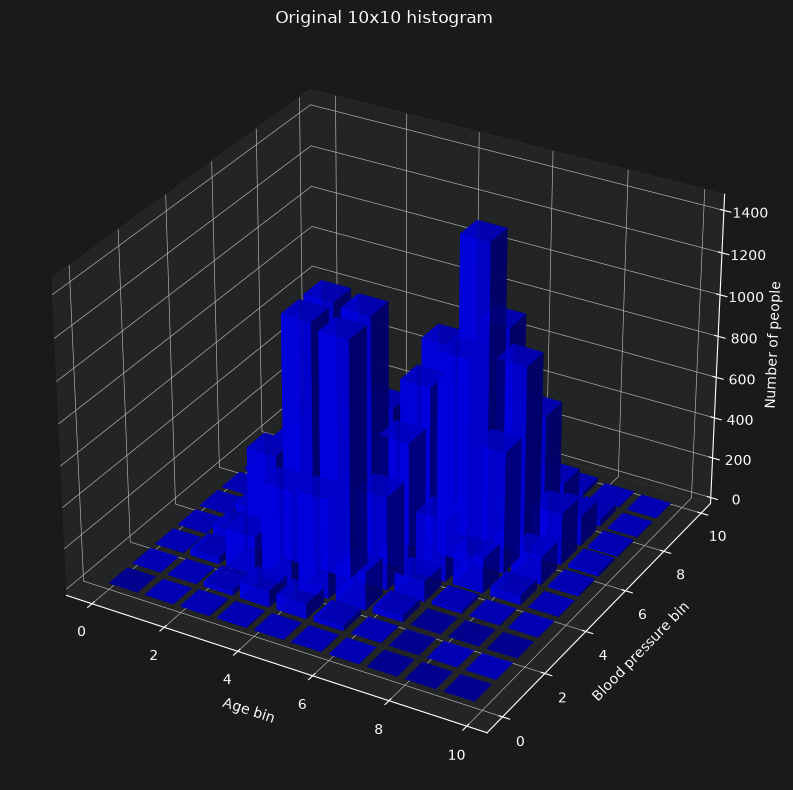

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# read data
np.random.seed(5489)  # bumpy's legacy random generator uses mersenne twister

data = pd.read_csv('data.csv')
data.columns = data.columns.str.strip()

#a. 10x10 histogram
counts, age_edges, bp_edges = np.histogram2d(
    data['Age'], data['BloodPressure'], bins=10
)
counts = counts.astype(int)
print('(a) Original histogram counts:')
print(counts)

# 3d histogram
x, y = np.meshgrid(np.arange(10), np.arange(10), indexing='ij')
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
ax.bar3d(x.ravel(), y.ravel(), np.zeros(100), 0.8, 0.8, counts.ravel(), color='blue', alpha=0.8)
ax.set_xlabel('Age bin')
ax.set_ylabel('Blood pressure bin')
ax.set_zlabel('Number of people')
ax.set_title('Original 10x10 histogram')
plt.tight_layout()
plt.show()

b. The sensitivity is **1**. If we add or remove one person, only one bin changes, and its count changes by exactly 1. So the L1 sensitivity of the histogram in the insertion/deletion case is $\Delta f=1$.

In [2]:
sensitivity = 1

c. We calculate $\alpha=e^{-\epsilon/\Delta f}=e^{-1.4}\approx0.2466$. To get two-sided geometric noise, we subtract two independent geometric random values for each bin. Then we add that noise to the original counts. Negative noisy counts are possible and are kept in the output.

In [3]:
# the difference of two independent one-sided geometric random variables
#has the two-sided geometric distribution needed for differential privacy.
epsilon = 1.4
alpha = np.exp(-epsilon / sensitivity)
noise1 = np.random.geometric(1 - alpha, size=counts.shape)
noise2 = np.random.geometric(1 - alpha, size=counts.shape)
noise = noise1 - noise2
noisy_counts = counts + noise
print('\n(c) Noisy histogram counts:')
print(noisy_counts)

np.savetxt('original_counts.csv', counts, fmt='%d', delimiter=',')
np.savetxt('noisy_counts.csv', noisy_counts, fmt='%d', delimiter=',')


(c) Noisy histogram counts:
[[   1    0    1    3    5    4    1    0    2    2]
 [   0    5   37   55   74   27    2   -2    1    2]
 [   6   23  190  491  438  172   26    2    1   -1]
 [   5   77  470 1180 1186  516   91   13    5    0]
 [   2   74  484 1149 1172  641  294  153   36    3]
 [   2   26  183  452  620  797  909  585  149   13]
 [   0    2   32   99  301  985 1443  955  214   18]
 [   1    0    0   15  169  591  910  582  158   20]
 [   0    1    0    3   46  137  253  147   31    4]
 [  -1   -1    0    1    2   10   16    9    2   -1]]


d. We draw the original counts in **blue** and the noisy counts in **yellow**, next to each other in one 3d plot. The added noise is small compared with the largest bin counts, so the overall shape stays very similar.

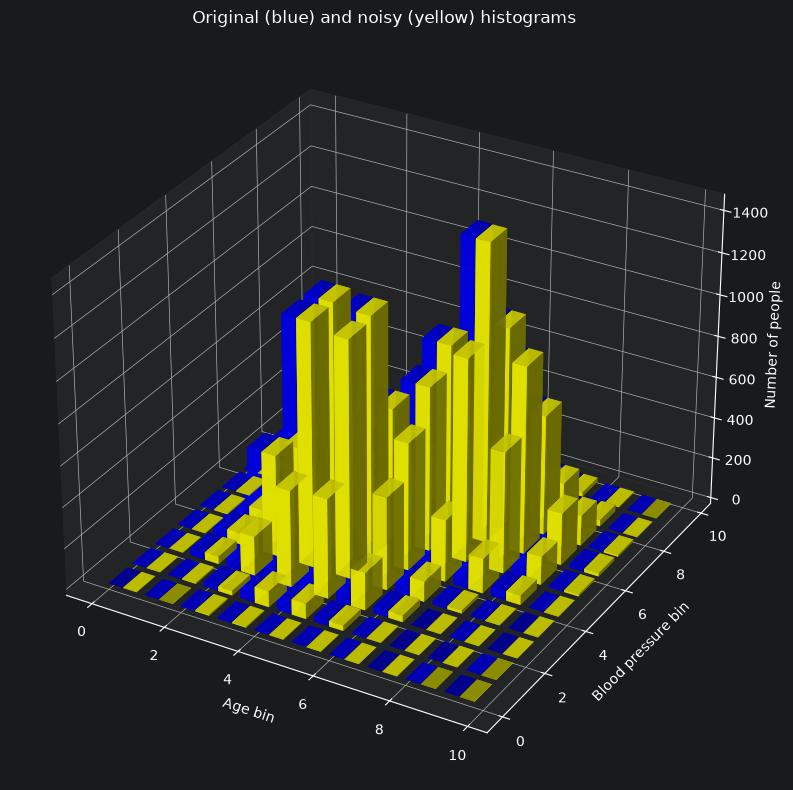

In [4]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.bar3d(x.ravel(), y.ravel(), np.zeros(100), 0.38, 0.8, counts.ravel(), color='blue', alpha=0.8)
ax.bar3d(x.ravel() + 0.4, y.ravel(), np.zeros(100), 0.38, 0.8, noisy_counts.ravel(), color='yellow', alpha=0.9)
ax.set_xlabel('Age bin')
ax.set_ylabel('Blood pressure bin')
ax.set_zlabel('Number of people')
ax.set_title('Original (blue) and noisy (yellow) histograms')
plt.tight_layout()
plt.show()